# Discriminant Analysis

In [1]:
from matplotlib import pyplot as plt
from plotly import express as px, graph_objects as go
from plotly.subplots import make_subplots

from sklearn import datasets
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.pipeline import Pipeline
from IPython.display import display_html
from pathlib import Path
from typing import List

import numpy as np
import os
import pandas as pd
import plotly.io as pio

from src.data import (
    loader as data_loader,
    sample as data_sample, 
)

## Utils

In [2]:
pio.renderers.default = "png"

def display_dfs_side_by_side(dfs, titles=None):
    titles = titles or [""] * len(dfs)
    html = "".join(
        f'<div style="display:inline-block;margin-right:20px;vertical-align:top">'
        f"<h4>{t}</h4>"
        f"{df.style.set_table_attributes('')._repr_html_()}</div>"
        for t, df in zip(titles, dfs)
    )
    display_html(html, raw=True)

## Data

### Cercles

Read: cercles3.txt


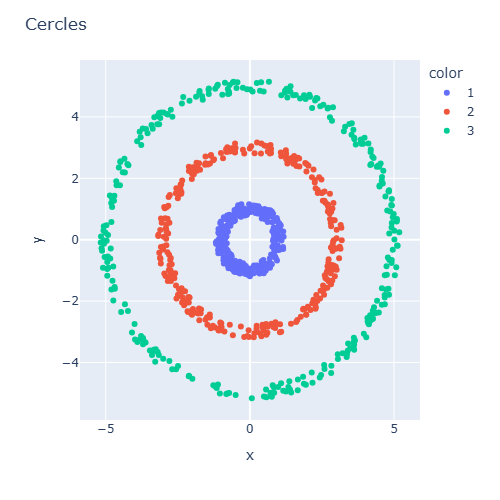

In [3]:
df_c = data_loader.load_cercles_ds()

# Plot data
fig = px.line(x=df_c["x1"], y=df_c["x2"], color=df_c["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="Cercles", width=500)

### Iris

Explained Variance Ratio: 97.77%


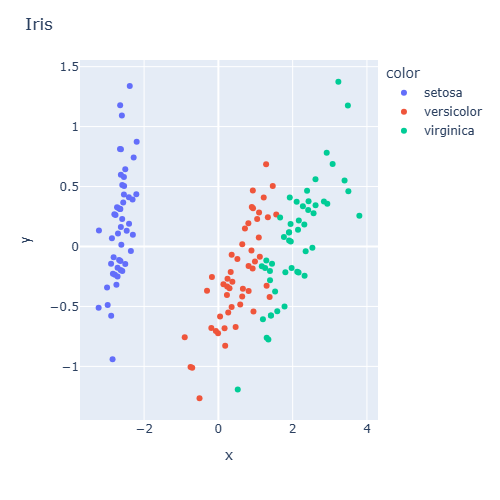

In [4]:
iris = datasets.load_iris()
assert iris is not None

X_raw = iris.data
iris_targets = iris.target
iris_target_names = iris.target_names

# PCA to keep first 2 principal components
pca = PCA(n_components=2)
pca.fit(X_raw)
total_explained_variance_ratio_ = np.sum(pca.explained_variance_ratio_)
assert total_explained_variance_ratio_ >= 0.95
print(f"Explained Variance Ratio: {total_explained_variance_ratio_:.2%}")

# Dimension reduced dataset
df_iris = pd.DataFrame(pca.transform(X_raw), columns=["x1", "x2"])
df_iris["y"] = iris_targets

# Plot data
fig = px.line(
    x=df_iris["x1"],
    y=df_iris["x2"],
    color=df_iris["y"].map(
        {i: iris_target_names[i] for i in range(len(iris_target_names))}
    ),
)
fig.update_traces(mode="markers")
fig.update_layout(title="Iris", width=500)

### Gaussian mixtures

#### With same covariance per class 

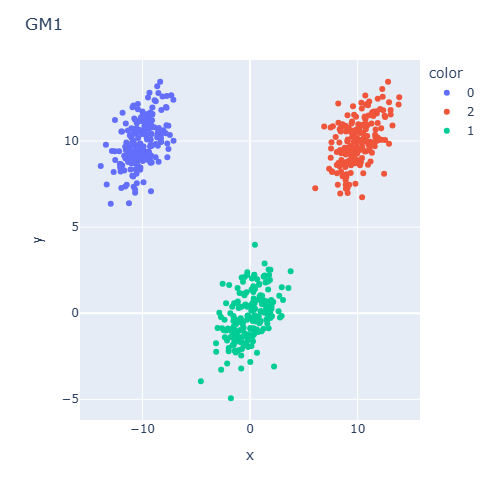

In [5]:
# Distributions Means
means = np.array([[-10, 10], [0, 0], [10, 10]])

# Distributions Covariances
cov = np.array([[2, 1], [1, 2]])
covs = [
    cov,
    cov,
    cov,
]

# Sample
df_gm1 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm1["x1"], y=df_gm1["x2"], color=df_gm1["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM1", width=500)

#### With different covariance per class 

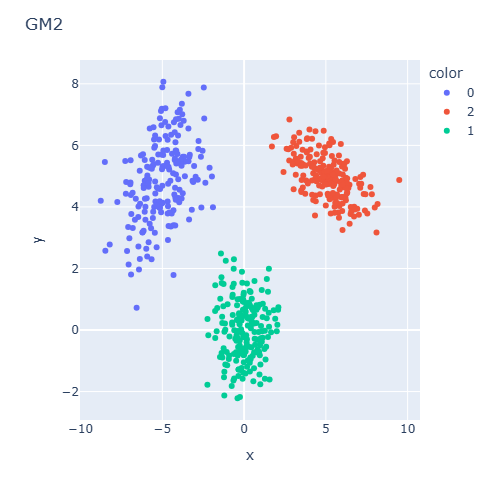

In [6]:
# Distributions Means
means = np.array([[-5, 5], [0, 0], [5, 5]])

# Distributions Covariances
covs = [
    np.array([[2, 1], [1, 2]]),
    np.array([[1, 0], [0, 1]]),
    np.array([[1.5, -0.5], [-0.5, 0.5]]),
]

# Sample
df_gm2 = data_sample.generate_gaussian_mixture_sample(
    means=means, 
    covs=covs, 
    size=600, 
)

# Plot data
fig = px.line(x=df_gm2["x1"], y=df_gm2["x2"], color=df_gm2["y"])
fig.update_traces(mode="markers")
fig.update_layout(title="GM2", width=500)

### Consolidated datasets

In [7]:
dict_df_ds = {
    "cercles": df_c,
    "iris": df_iris,
    "gm1": df_gm1,
    "gm2": df_gm2,
}
LIST_DS = [ds for ds in dict_df_ds]
print(LIST_DS)

['cercles', 'iris', 'gm1', 'gm2']


## Train/Test Split

In [8]:
def get_train_test_split(
    df: pd.DataFrame,
) -> dict:

    X_raw = df[["x1", "x2"]]
    y_raw = df["y"]
    labels = list(set(y_raw))

    # Train-Test Split
    X, X_test, y, y_test = train_test_split(
        X_raw,
        y_raw,
        test_size=0.25,
        stratify=y_raw,  # keep class proportions in both sets
        random_state=0,  # reproducibility
    )
    dict_split = {
        "train": {"X": X, "y": y, "labels": labels},
        "test": {"X": X_test, "y": y_test, "labels": labels},
    }
    return dict_split


DICT_DS_SPLIT = {n: get_train_test_split(df=dict_df_ds[n]) for n in dict_df_ds}

In [9]:
list_temp = [
    {
        "name": n,
        "split": t,
        "X": DICT_DS_SPLIT[n][t]["X"].shape,
        "y": DICT_DS_SPLIT[n][t]["y"].shape,
    }
    for n in DICT_DS_SPLIT.keys()
    for t in DICT_DS_SPLIT[n]
]
pd.DataFrame(list_temp)

,name,split,X,y
0,cercles,train,"(675, 2)","(675,)"
1,cercles,test,"(225, 2)","(225,)"
2,iris,train,"(112, 2)","(112,)"
3,iris,test,"(38, 2)","(38,)"
4,gm1,train,"(450, 2)","(450,)"
5,gm1,test,"(150, 2)","(150,)"
6,gm2,train,"(450, 2)","(450,)"
7,gm2,test,"(150, 2)","(150,)"


In [10]:
# [dict_ds_split[n]['train'] for n in dict_ds_split]
for n in DICT_DS_SPLIT:
    df_temp = pd.concat(
        [
            DICT_DS_SPLIT[n][t]["y"]
            .value_counts(normalize=True)
            .sort_index()
            .to_frame(name=f"{n}_{t}")
            .T
            for t in DICT_DS_SPLIT[n]
        ]
    )
    display(df_temp)
    print("+" * 50)

y,1,2,3
cercles_train,0.333333,0.333333,0.333333
cercles_test,0.333333,0.333333,0.333333


++++++++++++++++++++++++++++++++++++++++++++++++++


y,0,1,2
iris_train,0.330357,0.330357,0.339286
iris_test,0.342105,0.342105,0.315789


++++++++++++++++++++++++++++++++++++++++++++++++++


y,0,1,2
gm1_train,0.331111,0.337778,0.331111
gm1_test,0.333333,0.340000,0.326667


++++++++++++++++++++++++++++++++++++++++++++++++++


y,0,1,2
gm2_train,0.322222,0.326667,0.351111
gm2_test,0.326667,0.326667,0.346667


++++++++++++++++++++++++++++++++++++++++++++++++++


The percentage of each class in train & test sets is constant 

#

## Classifiers

### Models

LinearDiscriminantAnalysis (LDA) and Quadratic Discriminant Analysis (QDA) models are broadly defined in @notes.md

### Scikit-learn classes documentation

The documentation below was obtained using help(LinearDiscriminantAnalysis) and help(QuadraticDiscriminantAnalysis)

#### Classes

```
class LinearDiscriminantAnalysis(
    sklearn.base.ClassNamePrefixFeaturesOutMixin, 
    sklearn.linear_model._base.LinearClassifierMixin, 
    sklearn.base.TransformerMixin, 
    sklearn.base.BaseEstimator,
)
 |  LinearDiscriminantAnalysis(
 |      solver='svd',
 |      shrinkage=None,
 |      priors=None,
 |      n_components=None,
 |      store_covariance=False,
 |      tol=0.0001,
 |      covariance_estimator=None
 |  )
 |
 |  Linear Discriminant Analysis.
 |
 |  A classifier with a linear decision boundary, generated by fitting class
 |  conditional densities to the data and using Bayes' rule.
 |
 |  The model fits a Gaussian density to each class, assuming that all classes
 |  share the same covariance matrix.
 |
 |  The fitted model can also be used to reduce the dimensionality of the input
 |  by projecting it to the most discriminative directions, using the
 |  `transform` method.
```

````
class QuadraticDiscriminantAnalysis(DiscriminantAnalysisPredictionMixin, sklearn.base.ClassifierMixin, sklearn.base.BaseEstimator)
 |  QuadraticDiscriminantAnalysis(
 |      *,
 |      solver='svd',
 |      shrinkage=None,
 |      priors=None,
 |      reg_param=0.0,
 |      store_covariance=False,
 |      tol=0.0001,
 |      covariance_estimator=None
 |  )
 |
 |  Quadratic Discriminant Analysis.
 |
 |  A classifier with a quadratic decision boundary, generated
 |  by fitting class conditional densities to the data
 |  and using Bayes' rule.
 |
 |  The model fits a Gaussian density to each class.
```

#### Parameters

```
LinearDiscriminantAnalysis:

Parameters
 |  ----------
 |  solver : {'svd', 'lsqr', 'eigen'}, default='svd'
 |      Solver to use, possible values:
 |        - 'svd': Singular value decomposition (default).
 |          Does not compute the covariance matrix, therefore this solver is
 |          recommended for data with a large number of features.
 |        - 'lsqr': Least squares solution.
 |          Can be combined with shrinkage or custom covariance estimator.
 |        - 'eigen': Eigenvalue decomposition.
 |          Can be combined with shrinkage or custom covariance estimator.
 |
 |      .. versionchanged:: 1.2
 |          `solver="svd"` now has experimental Array API support. See the
 |          :ref:`Array API User Guide <array_api>` for more details.
 |
 |  shrinkage : 'auto' or float, default=None
 |      Shrinkage parameter, possible values:
 |        - None: no shrinkage (default).
 |        - 'auto': automatic shrinkage using the Ledoit-Wolf lemma.
 |        - float between 0 and 1: fixed shrinkage parameter.
 |
 |      This should be left to None if `covariance_estimator` is used.
 |      Note that shrinkage works only with 'lsqr' and 'eigen' solvers.
 |
 |      For a usage example, see
 |      :ref:`sphx_glr_auto_examples_classification_plot_lda.py`.
 |
 |  priors : array-like of shape (n_classes,), default=None
 |      The class prior probabilities. By default, the class proportions are
 |      inferred from the training data.
 |
 |  n_components : int, default=None
 |      Number of components (<= min(n_classes - 1, n_features)) for
 |      dimensionality reduction. If None, will be set to
 |      min(n_classes - 1, n_features). This parameter only affects the
 |      `transform` method.
 |
 |      For a usage example, see
 |      :ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.
 |
 |  store_covariance : bool, default=False
 |      If True, explicitly compute the weighted within-class covariance
 |      matrix when solver is 'svd'. The matrix is always computed
 |      and stored for the other solvers.
 |
 |      .. versionadded:: 0.17
 |
 |  tol : float, default=1.0e-4
 |      Absolute threshold for a singular value of X to be considered
 |      significant, used to estimate the rank of X. Dimensions whose
 |      singular values are non-significant are discarded. Only used if
 |      solver is 'svd'.
 |
 |      .. versionadded:: 0.17
 |
 |  covariance_estimator : covariance estimator, default=None
 |      If not None, `covariance_estimator` is used to estimate
 |      the covariance matrices instead of relying on the empirical
 |      covariance estimator (with potential shrinkage).
 |      The object should have a fit method and a ``covariance_`` attribute
 |      like the estimators in :mod:`sklearn.covariance`.
 |      if None the shrinkage parameter drives the estimate.
 |
 |      This should be left to None if `shrinkage` is used.
 |      Note that `covariance_estimator` works only with 'lsqr' and 'eigen'
 |      solvers.
```

```
QuadraticDiscriminantAnalysis:

Parameters
 |  ----------
 |  solver : {'svd', 'eigen'}, default='svd'
 |      Solver to use, possible values:
 |        - 'svd': Singular value decomposition (default).
 |          Does not compute the covariance matrix, therefore this solver is
 |          recommended for data with a large number of features.
 |        - 'eigen': Eigenvalue decomposition.
 |          Can be combined with shrinkage or custom covariance estimator.
 |
 |  shrinkage : 'auto' or float, default=None
 |      Shrinkage parameter, possible values:
 |        - None: no shrinkage (default).
 |        - 'auto': automatic shrinkage using the Ledoit-Wolf lemma.
 |        - float between 0 and 1: fixed shrinkage parameter.
 |
 |        Enabling shrinkage is expected to improve the model when some
 |        classes have a relatively small number of training data points
 |        compared to the number of features by mitigating overfitting during
 |        the covariance estimation step.
 |
 |      This should be left to `None` if `covariance_estimator` is used.
 |      Note that shrinkage works only with 'eigen' solver.
 |
 |  priors : array-like of shape (n_classes,), default=None
 |      Class priors. By default, the class proportions are inferred from the
 |      training data.
 |
 |  reg_param : float, default=0.0
 |      Regularizes the per-class covariance estimates by transforming S2 as
 |      ``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,
 |      where S2 corresponds to the `scaling_` attribute of a given class.
 |
 |  store_covariance : bool, default=False
 |      If True, the class covariance matrices are explicitly computed and
 |      stored in the `self.covariance_` attribute.
 |
 |      .. versionadded:: 0.17
 |
 |  tol : float, default=1.0e-4
 |      Absolute threshold for the covariance matrix to be considered rank
 |      deficient after applying some regularization (see `reg_param`) to each
 |      `Sk` where `Sk` represents covariance matrix for k-th class. This
 |      parameter does not affect the predictions. It controls when a warning
 |      is raised if the covariance matrix is not full rank.
 |
 |      .. versionadded:: 0.17
 |
 |  covariance_estimator : covariance estimator, default=None
 |      If not None, `covariance_estimator` is used to estimate the covariance
 |      matrices instead of relying on the empirical covariance estimator
 |      (with potential shrinkage).  The object should have a fit method and
 |      a ``covariance_`` attribute like the estimators in
 |      :mod:`sklearn.covariance`. If None the shrinkage parameter drives the
 |      estimate.
 |
 |      This should be left to `None` if `shrinkage` is used.
 |      Note that `covariance_estimator` works only with the 'eigen' solver.
```

#### Attributes

```
LinearDiscriminantAnalysis:

Attributes
 |  ----------
 |  coef_ : ndarray of shape (n_features,) or (n_classes, n_features)
 |      Weight vector(s).
 |
 |  intercept_ : ndarray of shape (n_classes,)
 |      Intercept term.
 |
 |  covariance_ : array-like of shape (n_features, n_features)
 |      Weighted within-class covariance matrix. It corresponds to
 |      `sum_k prior_k * C_k` where `C_k` is the covariance matrix of the
 |      samples in class `k`. The `C_k` are estimated using the (potentially
 |      shrunk) biased estimator of covariance. If solver is 'svd', only
 |      exists when `store_covariance` is True.
 |
 |  explained_variance_ratio_ : ndarray of shape (n_components,)
 |      Percentage of variance explained by each of the selected components.
 |      If ``n_components`` is not set then all components are stored and the
 |      sum of explained variances is equal to 1.0. Only available when eigen
 |      or svd solver is used.
 |
 |  means_ : array-like of shape (n_classes, n_features)
 |      Class-wise means.
 |
 |  priors_ : array-like of shape (n_classes,)
 |      Class priors (sum to 1).
 |
 |  scalings_ : array-like of shape (rank, n_classes - 1)
 |      Scaling of the features in the space spanned by the class centroids.
 |      Only available for 'svd' and 'eigen' solvers.
 |
 |  xbar_ : array-like of shape (n_features,)
 |      Overall mean. Only present if solver is 'svd'.
 |
 |  classes_ : array-like of shape (n_classes,)
 |      Unique class labels.
 |
 |  n_features_in_ : int
 |      Number of features seen during :term:`fit`.
 |
 |      .. versionadded:: 0.24
 |
 |  feature_names_in_ : ndarray of shape (`n_features_in_`,)
 |      Names of features seen during :term:`fit`. Defined only when `X`
 |      has feature names that are all strings.
 |
 |      .. versionadded:: 1.0
```

```
QuadraticDiscriminantAnalysis:

Attributes
 |  ----------
 |  covariance_ : list of len n_classes of ndarray             of shape (n_features, n_features)
 |      For each class, gives the covariance matrix estimated using the
 |      samples of that class. The estimates use the maximum likelihood
 |      (biased) covariance estimator. Only present if `store_covariance` is
 |      True.
 |
 |  means_ : array-like of shape (n_classes, n_features)
 |      Class-wise means.
 |
 |  priors_ : array-like of shape (n_classes,)
 |      Class priors (sum to 1).
 |
 |  rotations_ : list of len n_classes of ndarray of shape (n_features, n_k)
 |      For each class k an array of shape (n_features, n_k), where
 |      ``n_k = min(n_features, number of elements in class k)``
 |      It is the rotation of the Gaussian distribution, i.e. its
 |      principal axis. It corresponds to `V`, the matrix of eigenvectors
 |      coming from the SVD of `Xk = U S Vt` where `Xk` is the centered
 |      matrix of samples from class k.
 |
 |  scalings_ : list of len n_classes of ndarray of shape (n_k,)
 |      For each class, contains the scaling of
 |      the Gaussian distributions along its principal axes, i.e. the
 |      variance in the rotated coordinate system. It corresponds to `S^2 /
 |      n_samples`, where `S` is the diagonal matrix of singular values
 |      from the SVD of `Xk`, where `Xk` is the centered matrix of samples
 |      from class k.
 |
 |  classes_ : ndarray of shape (n_classes,)
 |      Unique class labels.
 |
 |  n_features_in_ : int
 |      Number of features seen during :term:`fit`.
 |
 |      .. versionadded:: 0.24
 |
 |  feature_names_in_ : ndarray of shape (`n_features_in_`,)
 |      Names of features seen during :term:`fit`. Defined only when `X`
 |      has feature names that are all strings.
```

### Classifiers Instance

## Fit Models

In [11]:
DICT_CLF = {}
DICT_DATA_PRED = {}
LIST_SPLITS = ["train", "test"]
CLF_NAMES = ["lda", "qda"]
for name_ds in DICT_DS_SPLIT:
    _dict_ds = DICT_DS_SPLIT[name_ds]
    DICT_DATA_PRED[name_ds] = {}
    _lda = LinearDiscriminantAnalysis(solver="svd", store_covariance=True)
    _qda = QuadraticDiscriminantAnalysis(store_covariance=True)
    _da_clfs = [
        ("lda", _lda),
        ("qda", _qda),
    ]
    pipe = Pipeline(steps=_da_clfs)
    DICT_CLF[name_ds] = {}
    for _row in _da_clfs:
        _clf_n, _clf_i = _row
        print(f"{name_ds} - Fit {_clf_n}")
        DICT_DATA_PRED[name_ds][_clf_n] = {}

        # Fit models on training set
        _clf_i.fit(_dict_ds["train"]["X"], _dict_ds["train"]["y"])
        DICT_CLF[name_ds][_clf_n] = _clf_i
        display(_clf_i)

        for _split in _dict_ds:
            # Models prediction on both sets
            _clf_i.predict(_dict_ds[_split]["X"])

            # Models prediction on both sets
            DICT_DATA_PRED[name_ds][_clf_n][_split] = {
                "predicted": _clf_i.predict(_dict_ds[_split]["X"]),
                "score": _clf_i.score(_dict_ds[_split]["X"], _dict_ds[_split]["y"]),
                "means": _clf_i.means_,
                "covariances": _clf_i.covariance_,
                "classes": _clf_i.classes_,
            }

    print("+" * 50)

cercles - Fit lda


,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int64](3,)","[1,2,3]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](3, 2)","[[-0.02,-0.01], [-0.04,-0.04], [ 0.06, 0.05]]"
"covariance_ covariance_: array-like of shape (n_features, n_features)Weighted within-class covariance matrix. It corresponds to`sum_k prior_k * C_k` where `C_k` is the covariance matrix of thesamples in class `k`. The `C_k` are estimated using the (potentiallyshrunk) biased estimator of covariance. If solver is 'svd', onlyexists when `store_covariance` is True.","ndarray[float64](2, 2)","[[ 6.08,-0.02], [-0.02, 5.45]]"


cercles - Fit qda


,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[int64](3,)","[1,2,3]"
"covariance_ covariance_: list of len n_classes of ndarray of shape (n_features, n_features)For each class, gives the covariance matrix estimated using thesamples of that class. The estimates use the maximum likelihood(biased) covariance estimator. Only present if `store_covariance` isTrue.",list,"[array([[0.495... 0.50671544]]), array([[ 4.66... 4.33339176]]), array([[13.09...11.51977839]])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"


++++++++++++++++++++++++++++++++++++++++++++++++++
iris - Fit lda


,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int64](3,)","[0,1,2]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](3, 2)","[[-15.76, 14.33], [ 4.04, -4.83], [ 11.41, -9.24]]"
"covariance_ covariance_: array-like of shape (n_features, n_features)Weighted within-class covariance matrix. It corresponds to`sum_k prior_k * C_k` where `C_k` is the covariance matrix of thesamples in class `k`. The `C_k` are estimated using the (potentiallyshrunk) biased estimator of covariance. If solver is 'svd', onlyexists when `store_covariance` is True.","ndarray[float64](2, 2)","[[0.34,0.18], [0.18,0.21]]"


iris - Fit qda


,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[int64](3,)","[0,1,2]"
"covariance_ covariance_: list of len n_classes of ndarray of shape (n_features, n_features)For each class, gives the covariance matrix estimated using thesamples of that class. The estimates use the maximum likelihood(biased) covariance estimator. Only present if `store_covariance` isTrue.",list,"[array([[0.056... 0.25400108]]), array([[0.398... 0.1607678 ]]), array([[0.544... 0.22471595]])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"


++++++++++++++++++++++++++++++++++++++++++++++++++
gm1 - Fit lda


,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int32](3,)","[0,1,2]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](3, 2)","[[-7.58, 5.49], [ 2.11,-4.6 ], [ 5.43,-0.79]]"
"covariance_ covariance_: array-like of shape (n_features, n_features)Weighted within-class covariance matrix. It corresponds to`sum_k prior_k * C_k` where `C_k` is the covariance matrix of thesamples in class `k`. The `C_k` are estimated using the (potentiallyshrunk) biased estimator of covariance. If solver is 'svd', onlyexists when `store_covariance` is True.","ndarray[float64](2, 2)","[[1.97,0.9 ], [0.9 ,1.86]]"


gm1 - Fit qda


,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[int32](3,)","[0,1,2]"
"covariance_ covariance_: list of len n_classes of ndarray of shape (n_features, n_features)For each class, gives the covariance matrix estimated using thesamples of that class. The estimates use the maximum likelihood(biased) covariance estimator. Only present if `store_covariance` isTrue.",list,"[array([[1.771... 1.77860685]]), array([[2.190... 2.02553212]]), array([[1.943... 1.7832547 ]])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"


++++++++++++++++++++++++++++++++++++++++++++++++++
gm2 - Fit lda


,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",True
,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int32](3,)","[0,1,2]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](3, 2)","[[-3.61, 1.63], [-0.08,-3.12], [ 3.38, 1.41]]"
"covariance_ covariance_: array-like of shape (n_features, n_features)Weighted within-class covariance matrix. It corresponds to`sum_k prior_k * C_k` where `C_k` is the covariance matrix of thesamples in class `k`. The `C_k` are estimated using the (potentiallyshrunk) biased estimator of covariance. If solver is 'svd', onlyexists when `store_covariance` is True.","ndarray[float64](2, 2)","[[1.44,0.05], [0.05,1.06]]"


gm2 - Fit qda


,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",True
,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.0
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Unique class labels.","ndarray[int32](3,)","[0,1,2]"
"covariance_ covariance_: list of len n_classes of ndarray of shape (n_features, n_features)For each class, gives the covariance matrix estimated using thesamples of that class. The estimates use the maximum likelihood(biased) covariance estimator. Only present if `store_covariance` isTrue.",list,"[array([[1.708... 1.84762051]]), array([[ 0.81... 0.90299591]]), array([[ 1.78... 0.47560637]])]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['x1','x2']"


++++++++++++++++++++++++++++++++++++++++++++++++++


## Gaussian Density Parameters

### Means

For both LDA and QDA, the means are estimated the same way.

So the values obtained for both methodologies should match 

In [12]:
for name_ds in DICT_DATA_PRED:
    list_df_means = []
    list_titles = []
    for _clf_n in DICT_DATA_PRED[name_ds]:
        set_temp = "train"

        # Utils
        df_f_temp = DICT_DS_SPLIT[name_ds][set_temp]["X"].copy()
        classes_temp = DICT_DATA_PRED[name_ds][_clf_n][set_temp]["classes"]
        count_features_temp_ = df_f_temp.shape[1]

        # Means
        mu_ys = DICT_DATA_PRED[name_ds][_clf_n][set_temp]["means"]
        assert mu_ys.shape == (len(classes_temp), count_features_temp_)
        df_means_temp = pd.DataFrame(
            mu_ys, columns=df_f_temp.columns, index=classes_temp
        )
        df_means_temp.index.name = "class"
        df_means_temp.columns.name = "features"
        list_df_means.append(df_means_temp)
        list_titles.append(f"{name_ds} - {_clf_n}")

    display_dfs_side_by_side(dfs=list_df_means, titles=list_titles)
    print("+" * 50)

features,x1,x2
class,,
1,-0.059773,0.064543
2,-0.147117,-0.063937
3,0.424952,0.419002
features,x1,x2
class,,
1,-0.059773,0.064543
2,-0.147117,-0.063937
3,0.424952,0.419002


++++++++++++++++++++++++++++++++++++++++++++++++++


features,x1,x2
class,,
0,-2.657439,0.190863
1,0.500951,-0.297901
2,2.171181,0.100646
features,x1,x2
class,,
0,-2.657439,0.190863
1,0.500951,-0.297901
2,2.171181,0.100646


++++++++++++++++++++++++++++++++++++++++++++++++++


features,x1,x2
class,,
0,-10.079646,9.962756
1,-0.042865,-0.144380
2,9.908083,9.927211
features,x1,x2
class,,
0,-10.079646,9.962756
1,-0.042865,-0.144380
2,9.908083,9.927211


++++++++++++++++++++++++++++++++++++++++++++++++++


features,x1,x2
class,,
0,-4.964270,4.839943
1,-0.107009,-0.018071
2,5.114801,4.944240
features,x1,x2
class,,
0,-4.964270,4.839943
1,-0.107009,-0.018071
2,5.114801,4.944240


++++++++++++++++++++++++++++++++++++++++++++++++++


One can see that for a given dataset the densities means are constant no matter LDA, QDA as expected

### Covariances

- For LDA, one supposes that the covariance matrix of features between each class is the same  
- For QDA, there is a covariance matrix of features per class

In [13]:
for name_ds in DICT_DATA_PRED:
    list_df_sigmas = []
    list_titles = []
    for _clf_n in DICT_DATA_PRED[name_ds]:
        set_temp = "train"

        # Utils
        df_f_temp = DICT_DS_SPLIT[name_ds][set_temp]["X"].copy()
        classes_temp = DICT_DATA_PRED[name_ds][_clf_n][set_temp]["classes"]
        count_labels = len(classes_temp)
        count_features_temp_ = df_f_temp.shape[1]

        # Means
        sigma_ys = DICT_DATA_PRED[name_ds][_clf_n][set_temp]["covariances"]
        if _clf_n == "lda":
            # Only one covariance matrix
            assert isinstance(sigma_ys, np.ndarray)
            assert sigma_ys.shape == (count_features_temp_, count_features_temp_)
            df_sigmas_temp = pd.DataFrame(
                sigma_ys, columns=df_f_temp.columns, index=df_f_temp.columns
            )
            list_df_sigmas.append(df_sigmas_temp)
            list_titles.append(f"{name_ds} - {_clf_n}")

        elif _clf_n == "qda":
            # One covariance matrix per class
            assert isinstance(sigma_ys, list)
            assert len(sigma_ys) == count_labels
            for _idx, _sigma_y in enumerate(sigma_ys):
                assert _sigma_y.shape == (count_features_temp_, count_features_temp_)
                df_sigmas_temp = pd.DataFrame(
                    _sigma_y, columns=df_f_temp.columns, index=df_f_temp.columns
                )
                list_df_sigmas.append(df_sigmas_temp)
                list_titles.append(f"{name_ds} - {_clf_n} - Class {classes_temp[_idx]}")
        else:
            raise ValueError(f"Unexpected classifier: {_clf_n}")

    display_dfs_side_by_side(dfs=list_df_sigmas, titles=list_titles)
    print("+" * 50)

,x1,x2
x1,6.084971,-0.015019
x2,-0.015019,5.453295
,x1,x2
x1,0.495685,0.038194
x2,0.038194,0.506715
,x1,x2
x1,4.665303,-0.047166
x2,-0.047166,4.333392
,x1,x2
x1,13.093925,-0.036087


++++++++++++++++++++++++++++++++++++++++++++++++++


,x1,x2
x1,0.335228,0.181651
x2,0.181651,0.213265
,x1,x2
x1,0.056596,0.069018
x2,0.069018,0.254001
,x1,x2
x1,0.398512,0.194088
x2,0.194088,0.160768
,x1,x2
x1,0.544908,0.279209


++++++++++++++++++++++++++++++++++++++++++++++++++


,x1,x2
x1,1.969883,0.897461
x2,0.897461,1.863552
,x1,x2
x1,1.771865,0.861018
x2,0.861018,1.778607
,x1,x2
x1,2.190278,0.958319
x2,0.958319,2.025532
,x1,x2
x1,1.943067,0.871820


++++++++++++++++++++++++++++++++++++++++++++++++++


,x1,x2
x1,1.443694,0.049335
x2,0.049335,1.057314
,x1,x2
x1,1.708759,0.749442
x2,0.749442,1.847621
,x1,x2
x1,0.817845,-0.027041
x2,-0.027041,0.902996
,x1,x2
x1,1.782717,-0.522110


++++++++++++++++++++++++++++++++++++++++++++++++++


As expected 

- For LDA there is only one features covariance matrix
- For QDA there is a features covariance matrix per class 

## Results

### Predicted Clusters

In [14]:
def _get_plot_data(
    ds: str,
    clf: str | None,
    split: str,
    y_type: str,
):
    # Checks
    assert ds in DICT_DS_SPLIT
    assert ds in DICT_DATA_PRED

    # Features
    Xs = DICT_DS_SPLIT[ds][split]["X"]

    # Classes
    if y_type == "actual":
        ys = DICT_DS_SPLIT[ds][split]["y"]
    elif y_type == "predicted":
        assert clf is not None
        ys = DICT_DATA_PRED[ds][clf][split]["predicted"]
    else:
        raise ValueError(f"Unexpected {y_type}")
    assert Xs.shape[0] == ys.shape[0]

    return Xs, ys


def plot_actual_vs_predicted_classes_1(
    split: str,
):

    # Figure
    nrows = len(LIST_DS)
    ncols = len(CLF_NAMES) + 1
    row_titles = tuple([ds.title() for ds in dict_df_ds])
    column_titles = tuple(["Actual"] + [clf.title() for clf in CLF_NAMES])

    fig = make_subplots(
        rows=nrows,
        cols=ncols,
        row_titles=row_titles,
        column_titles=column_titles,
    )

    # Actual vs Predicted Targets
    for _idx_row, ds in enumerate(LIST_DS):
        # Actual Classes
        Xs, ys_actual = _get_plot_data(ds=ds, clf=None, split=split, y_type="actual")
        trace_actual = go.Scatter(
            x=Xs["x1"],
            y=Xs["x2"],
            mode="markers",
            marker=dict(color=ys_actual),
            name="actual_target",
        )

        fig.add_trace(trace_actual, row=_idx_row + 1, col=1)

        # Predicted Classes
        for _idx_col, _name_clf in enumerate(CLF_NAMES):
            Xs, ys_pred = _get_plot_data(
                ds=ds, clf=_name_clf, split=split, y_type="predicted"
            )
            trace_pred = go.Scatter(
                x=Xs["x1"],
                y=Xs["x2"],
                mode="markers",
                marker=dict(color=ys_pred),
                name="predicted_target",
            )
            fig.add_trace(trace_pred, row=_idx_row + 1, col=_idx_col + 2)

    fig.update_layout(title=f"{split.title()} Set, Actual Vs Predicted Targets")
    fig.update_layout(width=500 * ncols, height=500 * nrows)
    return fig

### Train Set

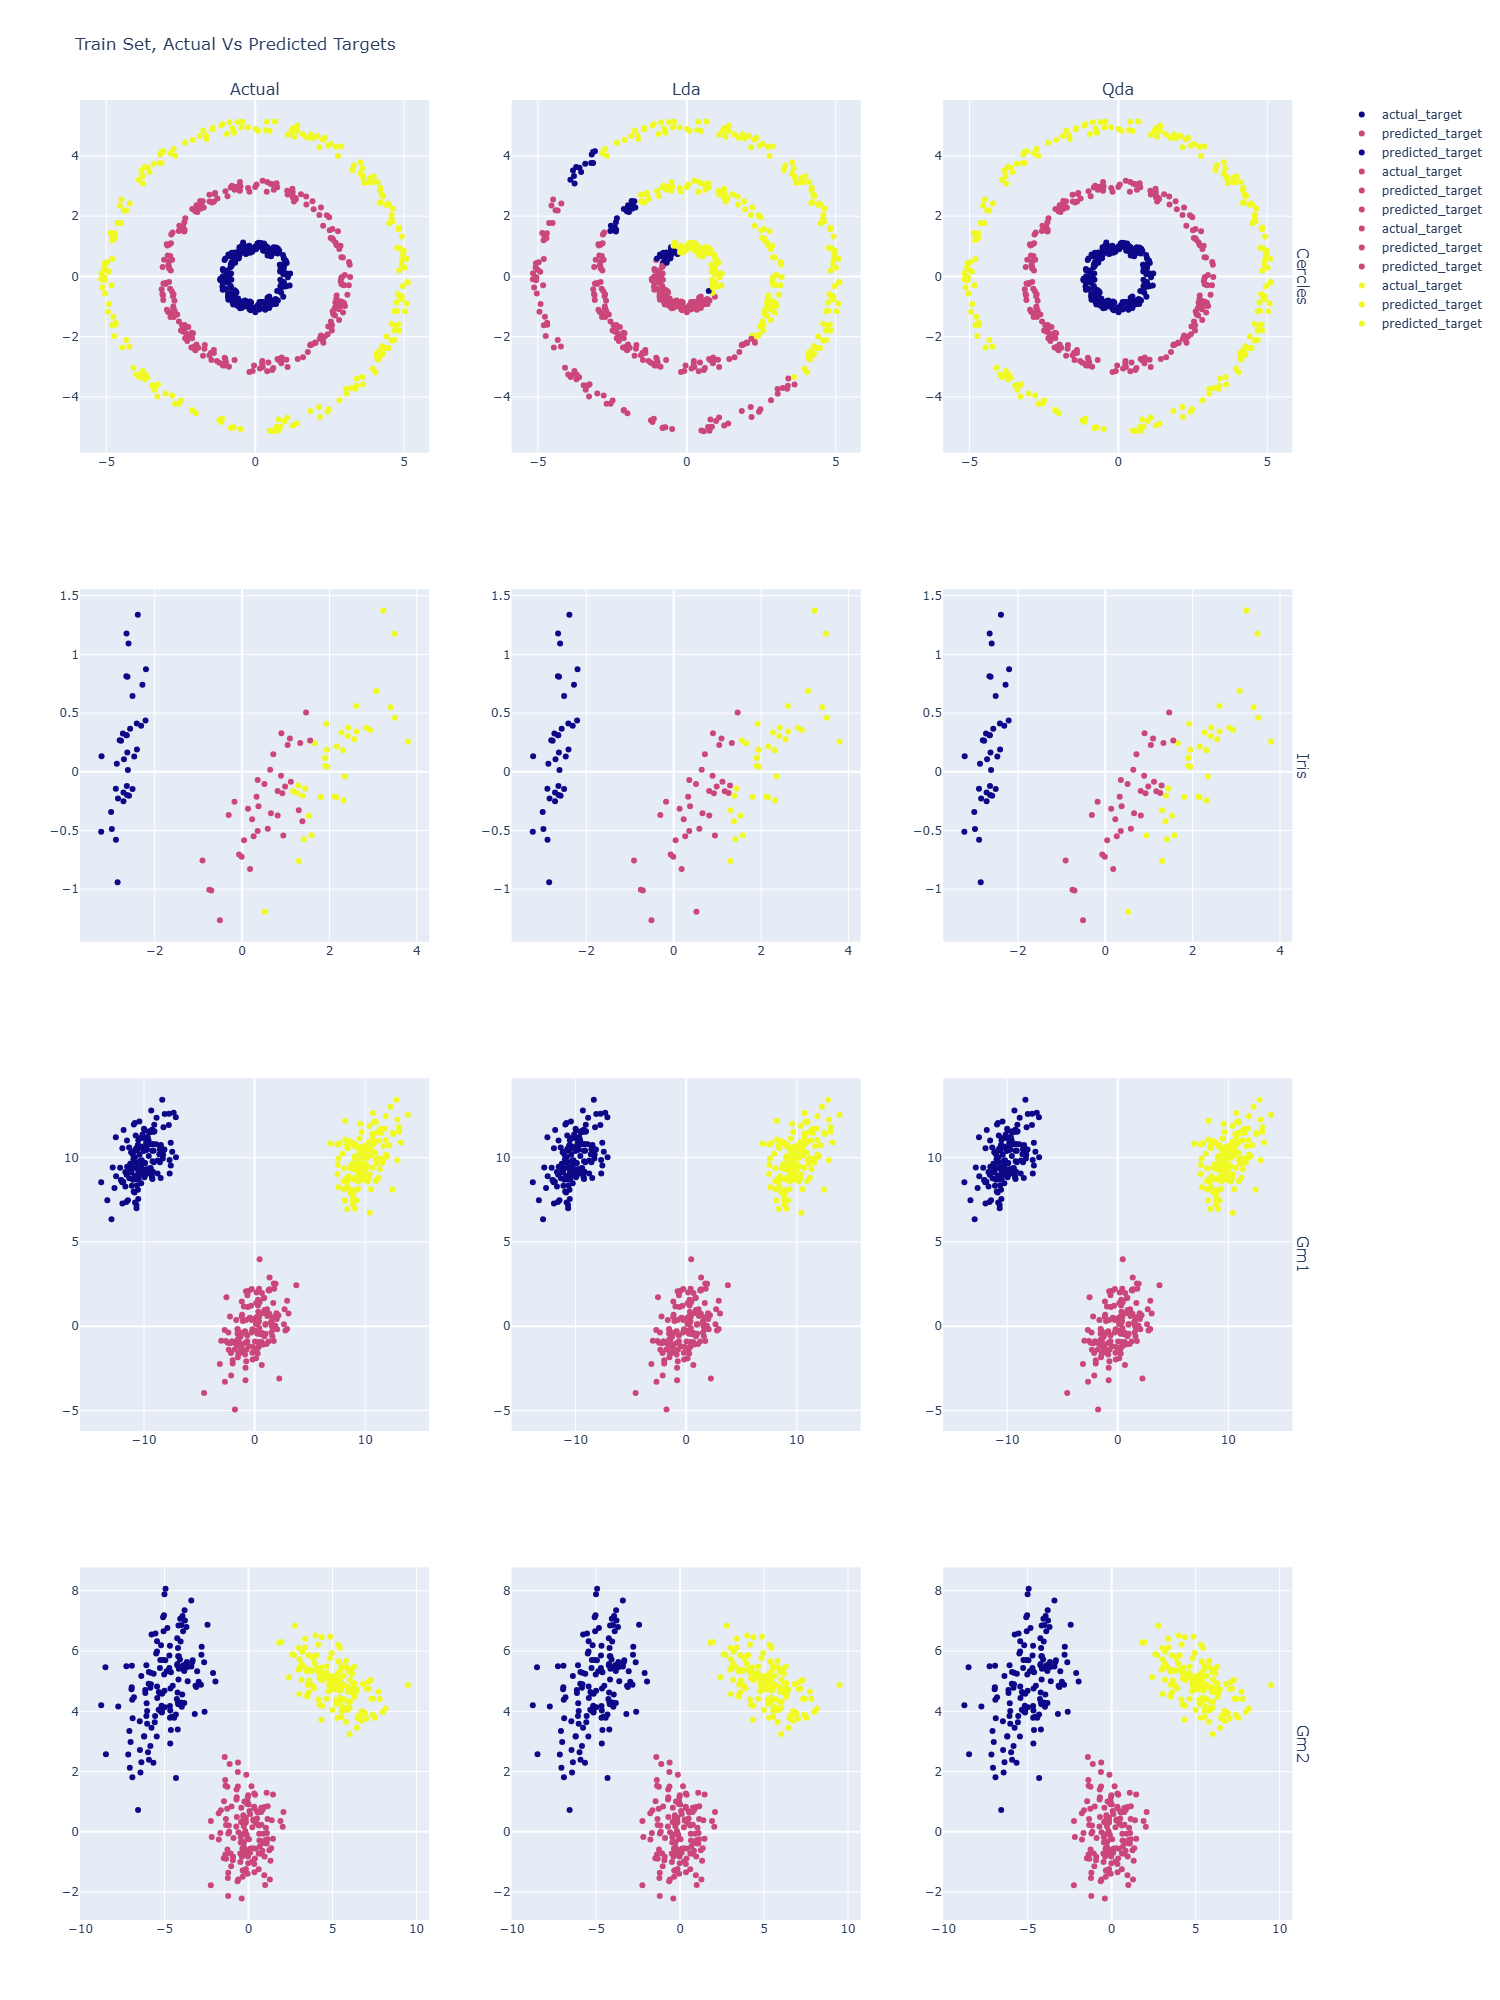

In [15]:
fig = plot_actual_vs_predicted_classes_1(split="train")
fig.show()

### Test Set

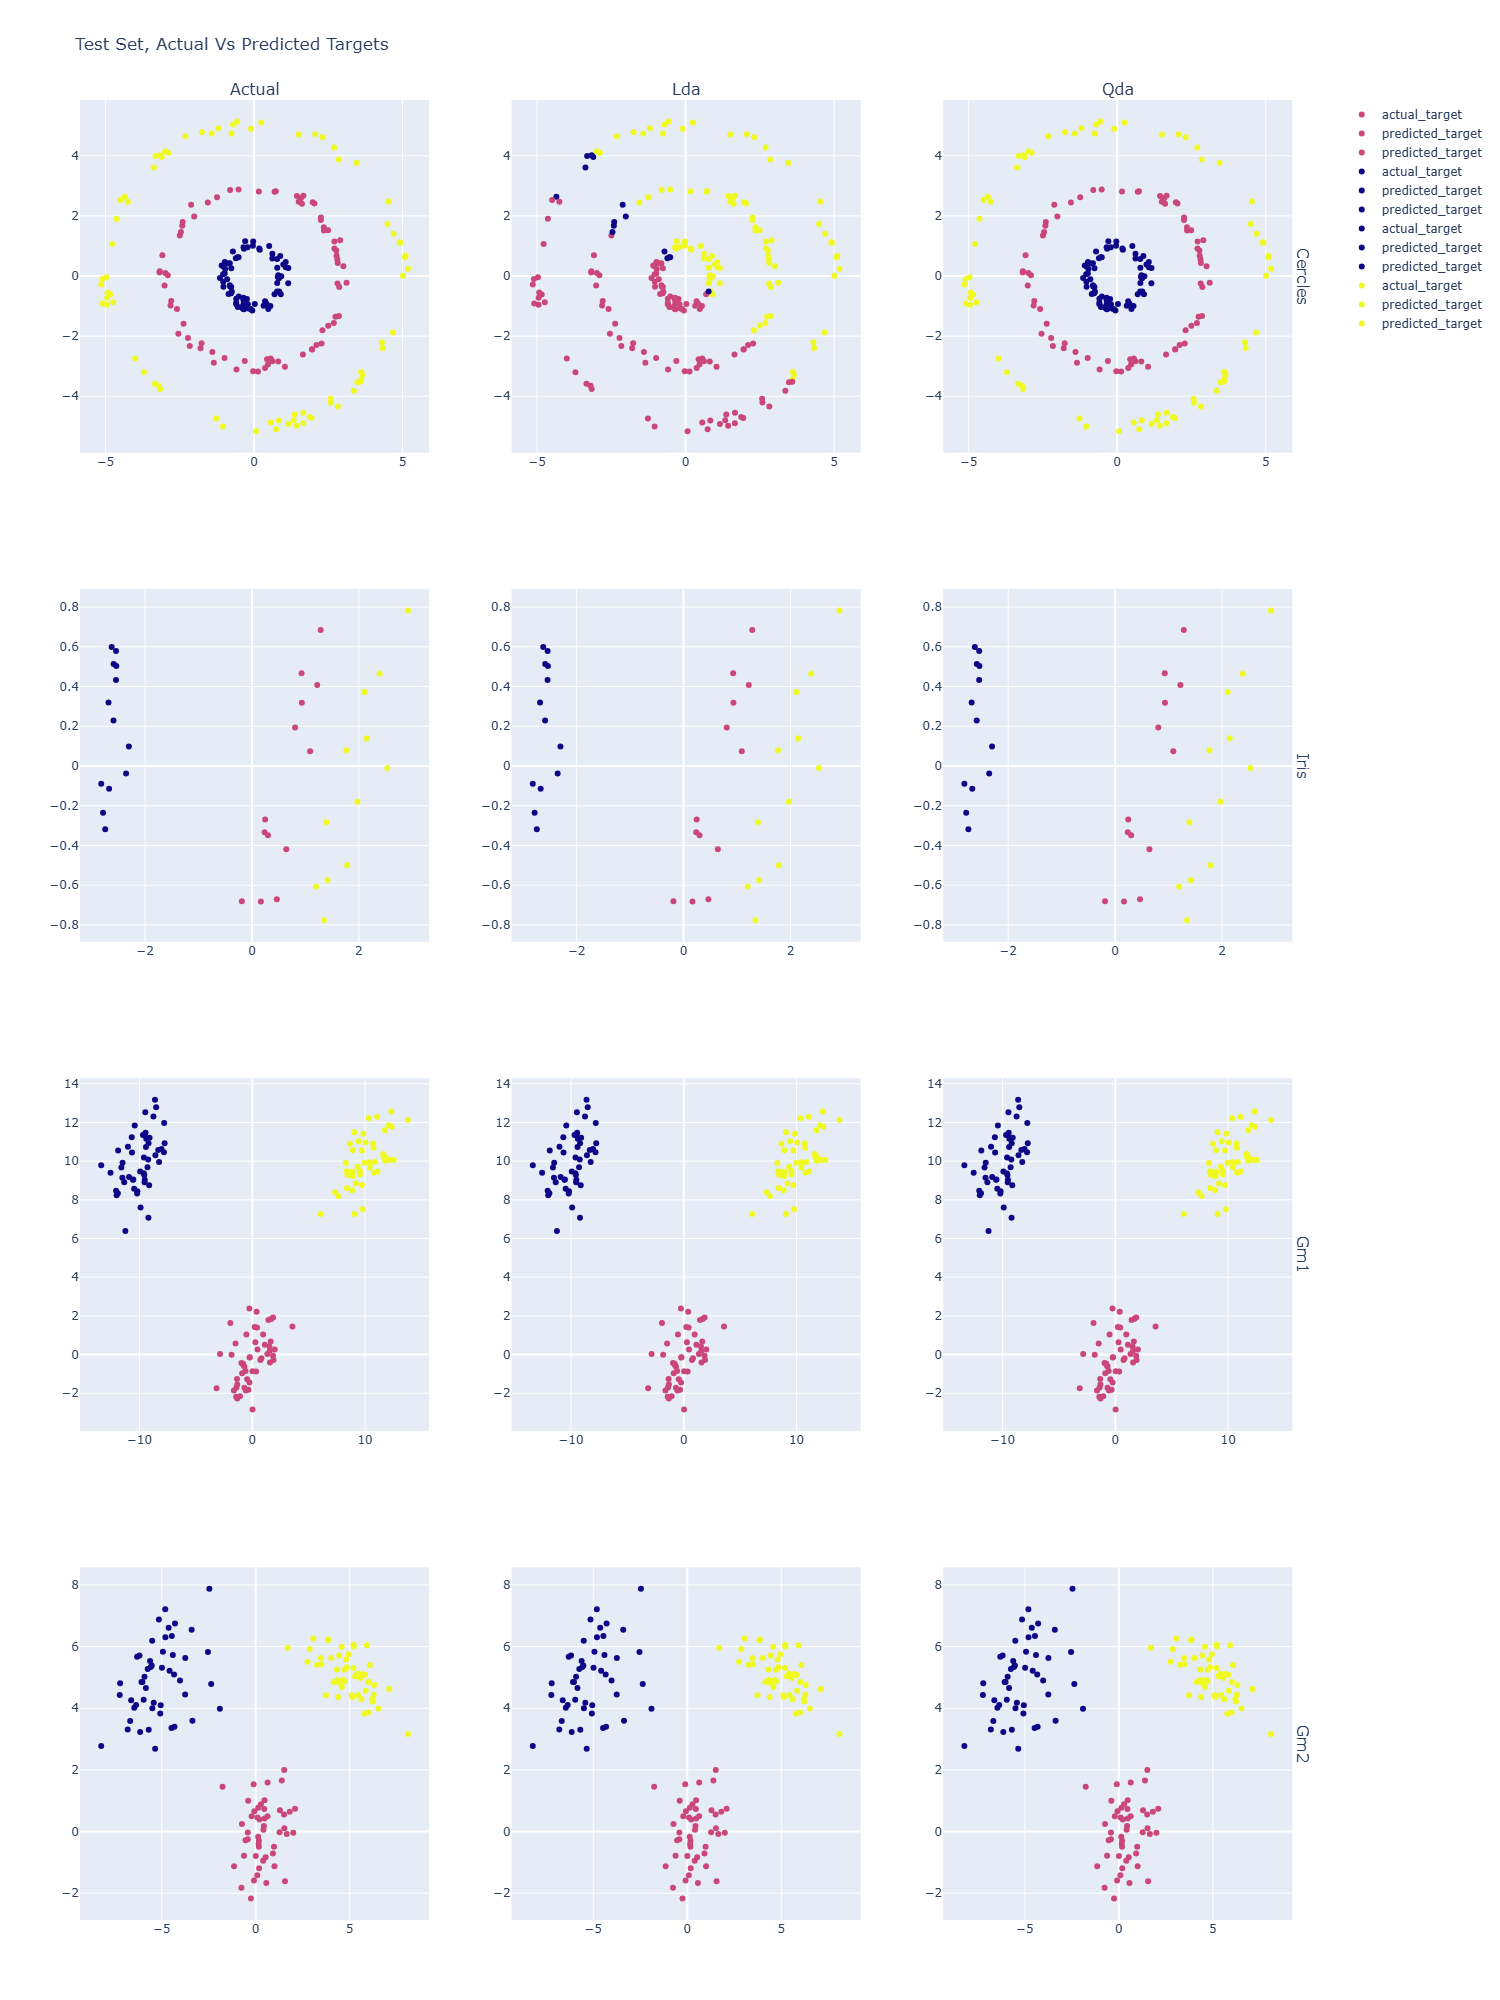

In [16]:
fig = plot_actual_vs_predicted_classes_1(split="test")
fig.show()

### Decision Boundary

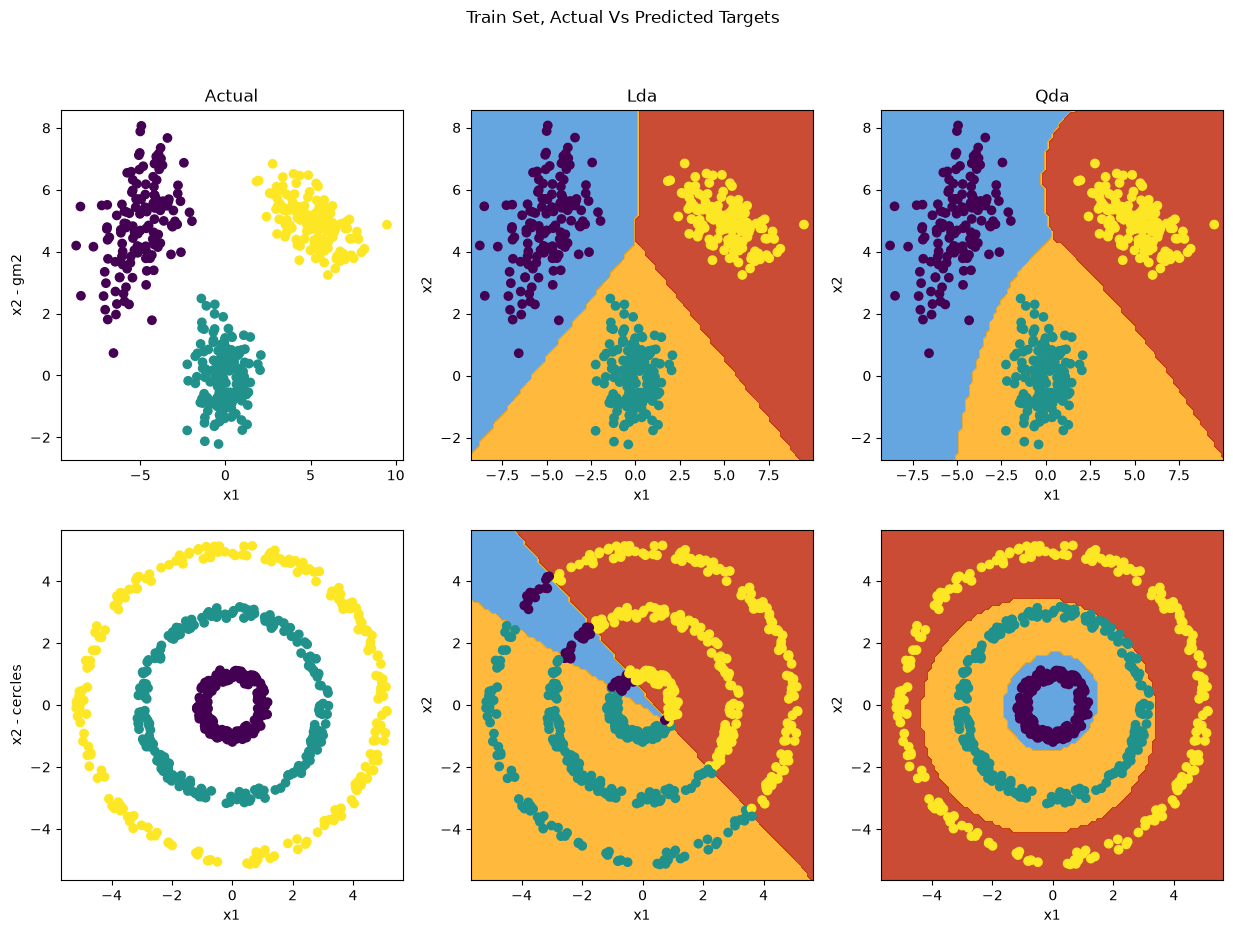

In [17]:
def plot_actual_vs_predicted_classes_2(
    split: str,
    list_ds: list | None,
):

    list_ds = list_ds or LIST_DS

    # Figure
    nrows = len(list_ds)
    ncols = len(CLF_NAMES) + 1
    fig, axes = plt.subplots(
        nrows=nrows,
        ncols=ncols,
        figsize=(5 * ncols, 5 * nrows),
        # widt
    )
    fig.suptitle(f"{split.title()} Set, Actual Vs Predicted Targets")

    # Actual vs Predicted Targets
    axes[0, 0].set_title("Actual")
    for _idx_row, ds in enumerate(list_ds):
        # Actual Classes
        Xs, ys_actual = _get_plot_data(ds=ds, clf=None, split=split, y_type="actual")
        axes[_idx_row][0].scatter(x=Xs["x1"], y=Xs["x2"], c=ys_actual)
        axes[_idx_row][0].set_ylabel(f"x2 - {ds}")
        axes[_idx_row][0].set_xlabel(f"x1")

        # Predicted Classes
        for _idx_col, _name_clf in enumerate(CLF_NAMES):
            if _idx_row == 0:
                axes[0, _idx_col + 1].set_title(_name_clf.title())
            Xs, ys_pred = _get_plot_data(
                ds=ds, clf=_name_clf, split=split, y_type="predicted"
            )
            axes[_idx_row][_idx_col + 1].scatter(x=Xs["x1"], y=Xs["x2"], c=ys_pred)

            # Decision From Fitted Classifier
            DecisionBoundaryDisplay.from_estimator(
                estimator=DICT_CLF[ds][_name_clf],
                X=Xs,
                response_method="predict",
                alpha=0.8,
                ax=axes[_idx_row][_idx_col + 1],
                eps=0.5,
            )

    return fig, axes


fig, axes = plot_actual_vs_predicted_classes_2(
    split="train",
    list_ds=[
        "gm2",
        "cercles",
    ],
)
plt.show();

As expected: 

- The Decision boundaries of LDA classifier are linear (cf notes)

    This highlights its poor performance on non linearly separable datasets like cercles

- The Decision boundaries of QDA classifier are quadratics (cf notes)
   
   This highlights its better performance on non linearly separable datasets like cercles

## Advantages of each method

- LDA: easier since we have less covariances matrix to estimate
- QDA: Perform better on datasets non linearly separable 